# Big Data


## dr inż. Patryk Jasik
### Division of Theoretical Physics and Quantum Information
### Institute of Physics and Computer Science
### Faculty of Applied Physics and Mathematics
### Gdansk University of Technology

In [1]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns

In [2]:
# Ustaw Seaborn jako domyslny styl dla wszystkich wykresów
sns.set()

In [3]:
# Wczytaj dane HR_dirty_data.txt
filename = 'HR_dirty_data.txt'
data_location = 'data/'
HR_dirty_data = pd.read_csv(data_location + filename, sep=';')

In [4]:
HR_dirty_data

,satisfaction_level,last_evaluation,number_project,average_montly_hours,time_spend_company,Work_accident,left,promotion_last_5years,sales,salary
0,0.38,0.53,2.0,157.0,3.0,0.0,1.0,0.0,sales,low
1,0.80,0.86,5.0,262.0,6.0,0.0,1.0,0.0,sales,medium
2,0.11,0.88,7.0,272.0,4.0,0.0,1.0,0.0,sales,medium
3,0.72,0.87,5.0,223.0,5.0,0.0,1.0,0.0,sales,low
4,0.37,0.52,2.0,159.0,3.0,0.0,1.0,0.0,sales,low
...,...,...,...,...,...,...,...,...,...,...
14994,0.40,0.57,2.0,151.0,3.0,0.0,1.0,0.0,support,low
14995,0.37,0.48,2.0,160.0,3.0,0.0,1.0,0.0,support,low
14996,0.37,0.53,2.0,143.0,3.0,0.0,1.0,0.0,support,low
14997,0.11,0.96,6.0,280.0,4.0,0.0,1.0,0.0,support,low


In [5]:
HR_dirty_data.describe()

,satisfaction_level,last_evaluation,number_project,average_montly_hours,time_spend_company,Work_accident,left,promotion_last_5years
count,14998.000000,14996.000000,14995.00000,14996.000000,14994.000000,14997.000000,14997.000000,14997.000000
mean,0.612826,0.716164,3.87129,201.046146,3.498133,0.144696,0.237981,0.021138
std,0.248637,0.171418,8.26312,49.941556,1.460305,0.352184,0.426175,0.144772
min,0.090000,0.360000,2.00000,96.000000,2.000000,-1.000000,-1.000000,-1.000000
25%,0.440000,0.560000,3.00000,156.000000,3.000000,0.000000,0.000000,0.000000
50%,0.640000,0.720000,4.00000,200.000000,3.000000,0.000000,0.000000,0.000000
75%,0.820000,0.870000,5.00000,245.000000,4.000000,0.000000,0.000000,0.000000
max,1.000000,1.700000,1004.00000,310.000000,10.000000,2.000000,1.000000,1.000000


In [6]:
HR_dirty_data.describe(include='all')

,satisfaction_level,last_evaluation,number_project,average_montly_hours,time_spend_company,Work_accident,left,promotion_last_5years,sales,salary
count,14998.000000,14996.000000,14995.00000,14996.000000,14994.000000,14997.000000,14997.000000,14997.000000,14997,14995
unique,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,20,8
top,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,sales,low
freq,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,4137,7311
mean,0.612826,0.716164,3.87129,201.046146,3.498133,0.144696,0.237981,0.021138,NaN,NaN
std,0.248637,0.171418,8.26312,49.941556,1.460305,0.352184,0.426175,0.144772,NaN,NaN
min,0.090000,0.360000,2.00000,96.000000,2.000000,-1.000000,-1.000000,-1.000000,NaN,NaN
25%,0.440000,0.560000,3.00000,156.000000,3.000000,0.000000,0.000000,0.000000,NaN,NaN
50%,0.640000,0.720000,4.00000,200.000000,3.000000,0.000000,0.000000,0.000000,NaN,NaN
75%,0.820000,0.870000,5.00000,245.000000,4.000000,0.000000,0.000000,0.000000,NaN,NaN


In [7]:
HR_dirty_data.info()

<class 'pandas.DataFrame'>
RangeIndex: 14999 entries, 0 to 14998
Data columns (total 10 columns):
 #   Column                 Non-Null Count  Dtype  
---  ------                 --------------  -----  
 0   satisfaction_level     14998 non-null  float64
 1   last_evaluation        14996 non-null  float64
 2   number_project         14995 non-null  float64
 3   average_montly_hours   14996 non-null  float64
 4   time_spend_company     14994 non-null  float64
 5   Work_accident          14997 non-null  float64
 6   left                   14997 non-null  float64
 7   promotion_last_5years  14997 non-null  float64
 8   sales                  14997 non-null  str    
 9   salary                 14995 non-null  str    
dtypes: float64(8), str(2)
memory usage: 1.1 MB


In [8]:
HR_dirty_data.left.value_counts()

left
 0.0    11424
 1.0     3571
-1.0        2
Name: count, dtype: int64

In [20]:
HR_dirty_data.Work_accident.value_counts()

Work_accident
 0.0    12826
 1.0     2169
 2.0        1
-1.0        1
Name: count, dtype: int64

In [21]:
HR_dirty_data.promotion_last_5years.value_counts()

promotion_last_5years
 0.0    14676
 1.0      319
-1.0        2
Name: count, dtype: int64

In [9]:
# czyszczenie danych
# last evaluation powinno być w zakresie 0-1, describe() pokazało,
# że maksymalna wartosc wynosi 1.7
# sprawdz ile wartosci jest powyzej 1
sum(HR_dirty_data['last_evaluation'] > 1)  # 2
#HR_dirty_data[HR_dirty_data['last_evaluation'] > 1]

2

In [10]:
mask = HR_dirty_data['last_evaluation'] > 1

In [11]:
mask.value_counts()

last_evaluation
False    14997
True         2
Name: count, dtype: int64

In [12]:
# Usunmy te wartosci (nie cale rekordy, tylko wartosci dla tej jednej kolumny)
mask = HR_dirty_data['last_evaluation'] > 1
HR_dirty_data.loc[mask, 'last_evaluation'] = np.nan

sum(HR_dirty_data['last_evaluation'] > 1)  # 0

0

In [13]:
HR_dirty_data.describe()

,satisfaction_level,last_evaluation,number_project,average_montly_hours,time_spend_company,Work_accident,left,promotion_last_5years
count,14998.000000,14994.000000,14995.00000,14996.000000,14994.000000,14997.000000,14997.000000,14997.000000
mean,0.612826,0.716053,3.87129,201.046146,3.498133,0.144696,0.237981,0.021138
std,0.248637,0.171150,8.26312,49.941556,1.460305,0.352184,0.426175,0.144772
min,0.090000,0.360000,2.00000,96.000000,2.000000,-1.000000,-1.000000,-1.000000
25%,0.440000,0.560000,3.00000,156.000000,3.000000,0.000000,0.000000,0.000000
50%,0.640000,0.720000,4.00000,200.000000,3.000000,0.000000,0.000000,0.000000
75%,0.820000,0.870000,5.00000,245.000000,4.000000,0.000000,0.000000,0.000000
max,1.000000,1.000000,1004.00000,310.000000,10.000000,2.000000,1.000000,1.000000


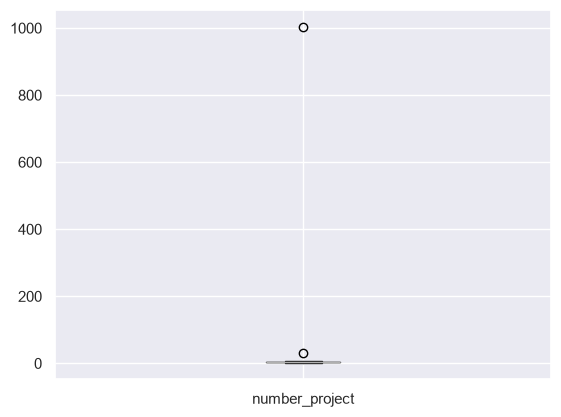

In [15]:
HR_dirty_data[['number_project']].boxplot()
plt.show()

In [16]:
# Sprawdzmy ile jest wartosci powyzej 100
sum(HR_dirty_data['number_project'] > 100)  # 1

1

In [17]:
# Usunmy tę jedna wartosc, analogicznie jak w przypadku last_evaluation
mask = HR_dirty_data['number_project'] > 100
HR_dirty_data.loc[mask, 'number_project'] = np.nan

In [18]:
sum(HR_dirty_data['number_project'] > 10)

1

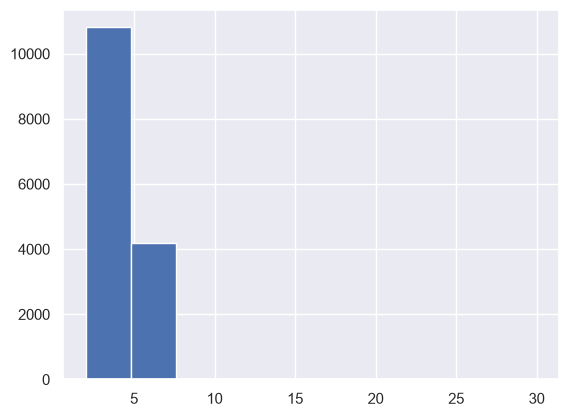

In [19]:
HR_dirty_data.number_project.hist()
plt.show()

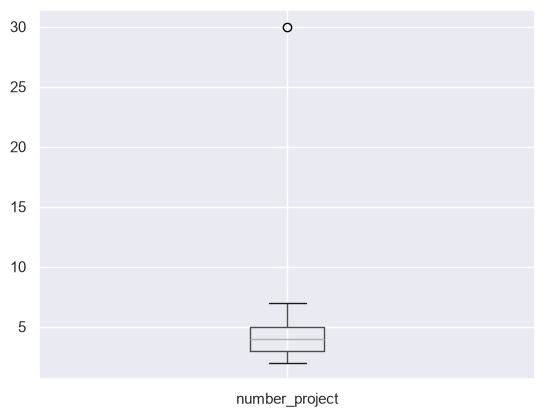

In [22]:
HR_dirty_data[['number_project']].boxplot()
plt.show()

In [23]:
mask = HR_dirty_data['number_project'] > 10
HR_dirty_data.loc[mask, 'number_project'] = np.nan

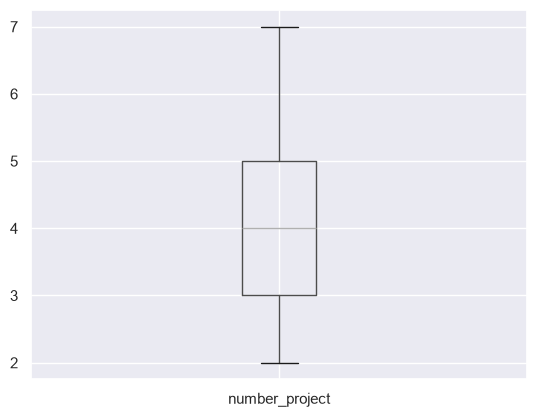

In [24]:
HR_dirty_data[['number_project']].boxplot()
plt.show()

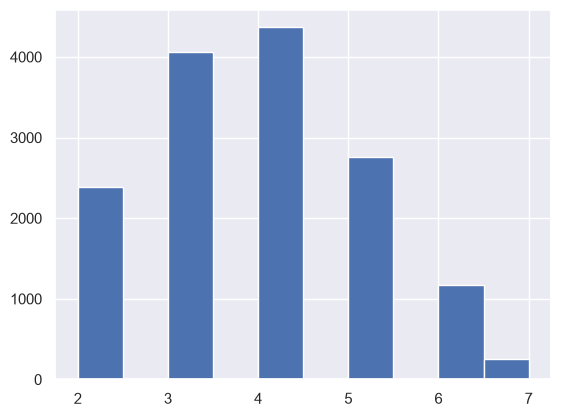

In [25]:
HR_dirty_data.number_project.hist()
plt.show()

In [26]:
HR_dirty_data.describe()

,satisfaction_level,last_evaluation,number_project,average_montly_hours,time_spend_company,Work_accident,left,promotion_last_5years
count,14998.000000,14994.000000,14993.000000,14996.000000,14994.000000,14997.000000,14997.000000,14997.000000
mean,0.612826,0.716053,3.802841,201.046146,3.498133,0.144696,0.237981,0.021138
std,0.248637,0.171150,1.232324,49.941556,1.460305,0.352184,0.426175,0.144772
min,0.090000,0.360000,2.000000,96.000000,2.000000,-1.000000,-1.000000,-1.000000
25%,0.440000,0.560000,3.000000,156.000000,3.000000,0.000000,0.000000,0.000000
50%,0.640000,0.720000,4.000000,200.000000,3.000000,0.000000,0.000000,0.000000
75%,0.820000,0.870000,5.000000,245.000000,4.000000,0.000000,0.000000,0.000000
max,1.000000,1.000000,7.000000,310.000000,10.000000,2.000000,1.000000,1.000000


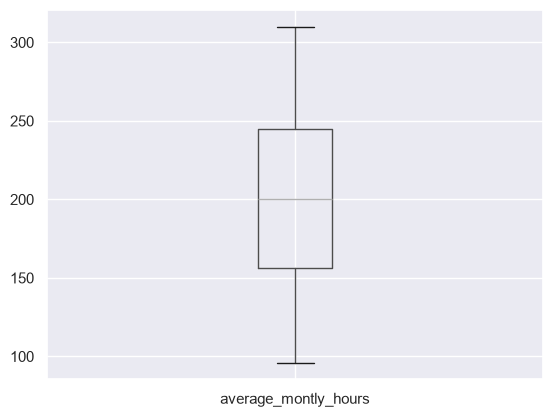

In [27]:
HR_dirty_data[['average_montly_hours']].boxplot()
plt.show()

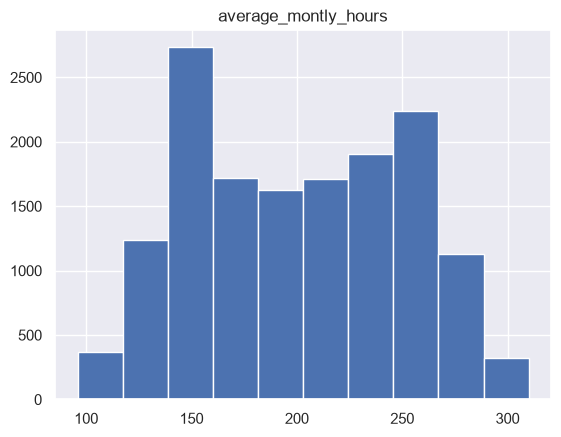

In [28]:
HR_dirty_data[['average_montly_hours']].hist()
plt.show()

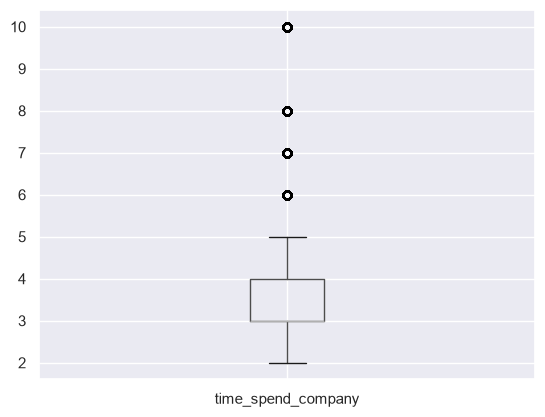

In [29]:
HR_dirty_data[['time_spend_company']].boxplot()
plt.show()

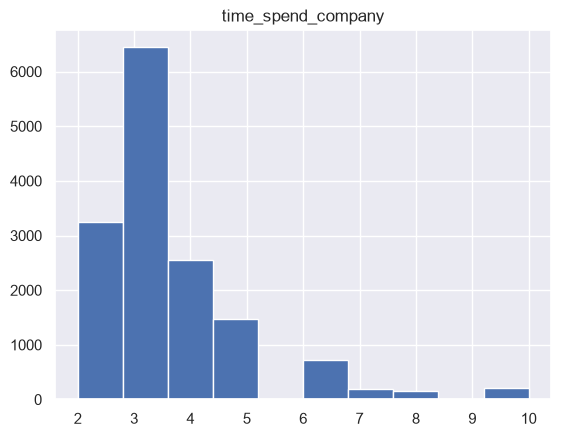

In [30]:
HR_dirty_data[['time_spend_company']].hist()
plt.show()

In [31]:
# Zmienne Work_accident, left i promotion_last_5years maja wartosci -1,
# ktore sa niedopusczalne, poniewaz sa to zmienne logiczne o wartosciach 0 lub 1.
# Byc moze ktos wprowadzil je przez przypadek zamiast 0, jednakze nie mozemy tego zalozyc
# bez porozumienia sie z wlascicielem danych. W zwiazku z tym, usunmy wszystkie wartosci -1 z tych zmiennych
mask = HR_dirty_data['Work_accident'] < 0
HR_dirty_data.loc[mask, 'Work_accident'] = np.nan

mask = HR_dirty_data['left'] < 0
HR_dirty_data.loc[mask, 'left'] = np.nan

mask = HR_dirty_data['promotion_last_5years'] < 0
HR_dirty_data.loc[mask, 'promotion_last_5years'] = np.nan

In [32]:
HR_dirty_data.describe()

,satisfaction_level,last_evaluation,number_project,average_montly_hours,time_spend_company,Work_accident,left,promotion_last_5years
count,14998.000000,14994.000000,14993.000000,14996.000000,14994.000000,14996.000000,14995.000000,14995.000000
mean,0.612826,0.716053,3.802841,201.046146,3.498133,0.144772,0.238146,0.021274
std,0.248637,0.171150,1.232324,49.941556,1.460305,0.352072,0.425963,0.144300
min,0.090000,0.360000,2.000000,96.000000,2.000000,0.000000,0.000000,0.000000
25%,0.440000,0.560000,3.000000,156.000000,3.000000,0.000000,0.000000,0.000000
50%,0.640000,0.720000,4.000000,200.000000,3.000000,0.000000,0.000000,0.000000
75%,0.820000,0.870000,5.000000,245.000000,4.000000,0.000000,0.000000,0.000000
max,1.000000,1.000000,7.000000,310.000000,10.000000,2.000000,1.000000,1.000000


In [33]:
HR_dirty_data.Work_accident.value_counts()

Work_accident
0.0    12826
1.0     2169
2.0        1
Name: count, dtype: int64

In [34]:
# Ponadto zmienna Work_accident ma wartosc maksymalna = 2, co rowniez
# jest nie do przyjecia z tego samego powodu co wyzej, usunmy wartosci > 1
mask = HR_dirty_data['Work_accident'] > 1
HR_dirty_data.loc[mask, 'Work_accident'] = np.nan

HR_dirty_data.describe()

,satisfaction_level,last_evaluation,number_project,average_montly_hours,time_spend_company,Work_accident,left,promotion_last_5years
count,14998.000000,14994.000000,14993.000000,14996.000000,14994.000000,14995.000000,14995.000000,14995.000000
mean,0.612826,0.716053,3.802841,201.046146,3.498133,0.144648,0.238146,0.021274
std,0.248637,0.171150,1.232324,49.941556,1.460305,0.351758,0.425963,0.144300
min,0.090000,0.360000,2.000000,96.000000,2.000000,0.000000,0.000000,0.000000
25%,0.440000,0.560000,3.000000,156.000000,3.000000,0.000000,0.000000,0.000000
50%,0.640000,0.720000,4.000000,200.000000,3.000000,0.000000,0.000000,0.000000
75%,0.820000,0.870000,5.000000,245.000000,4.000000,0.000000,0.000000,0.000000
max,1.000000,1.000000,7.000000,310.000000,10.000000,1.000000,1.000000,1.000000


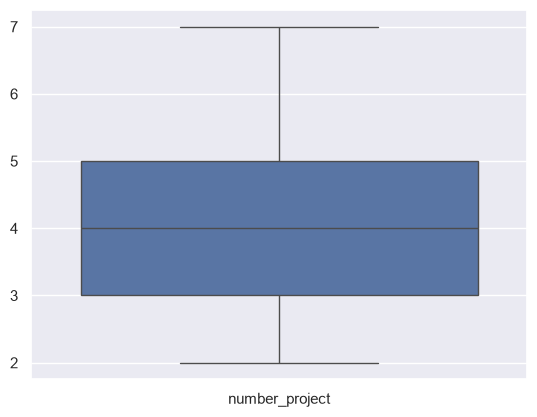

In [35]:
sns.boxplot(HR_dirty_data[['number_project']])
plt.show()

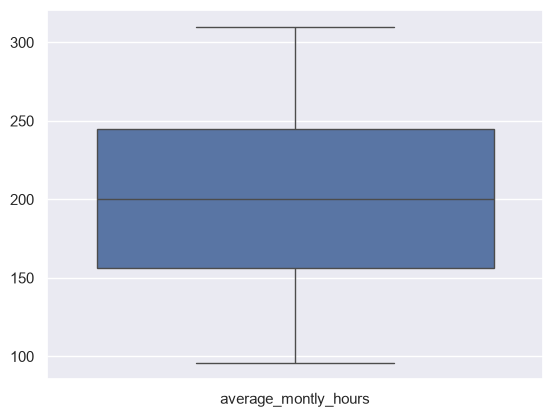

In [36]:
sns.boxplot(HR_dirty_data[['average_montly_hours']])
plt.show()

In [37]:
# salary #
#HR_dirty_data['salary'].unique()
HR_dirty_data['salary'] = HR_dirty_data['salary'].str.replace(" ", "")
HR_dirty_data['salary'].value_counts()

salary
low       7314
medium    6442
high      1237
Medium       1
mediu        1
Name: count, dtype: int64

In [38]:
HR_dirty_data['salary'].value_counts()

salary
low       7314
medium    6442
high      1237
Medium       1
mediu        1
Name: count, dtype: int64

In [39]:
salary_map = {'mediu': 'medium', 'Medium': 'medium'}
HR_dirty_data['salary'].replace(salary_map, inplace=True)
HR_dirty_data['salary'].value_counts()

C:\Users\studentwftims.LAB\AppData\Local\Temp\ipykernel_10172\569070054.py:2: ChainedAssignmentError: A value is being set on a copy of a DataFrame or Series through chained assignment using an inplace method.
Such inplace method never works to update the original DataFrame or Series, because the intermediate object on which we are setting values always behaves as a copy (due to Copy-on-Write).

For example, when doing 'df[col].method(value, inplace=True)', try using 'df.method({col: value}, inplace=True)' instead, to perform the operation inplace on the original object, or try to avoid an inplace operation using 'df[col] = df[col].method(value)'.

See the documentation for a more detailed explanation: https://pandas.pydata.org/pandas-docs/stable/user_guide/copy_on_write.html
  HR_dirty_data['salary'].replace(salary_map, inplace=True)


salary
low       7314
medium    6442
high      1237
Medium       1
mediu        1
Name: count, dtype: int64

In [40]:
HR_dirty_data.describe(include='all')

,satisfaction_level,last_evaluation,number_project,average_montly_hours,time_spend_company,Work_accident,left,promotion_last_5years,sales,salary
count,14998.000000,14994.000000,14993.000000,14996.000000,14994.000000,14995.000000,14995.000000,14995.000000,14997,14995
unique,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,20,5
top,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,sales,low
freq,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,4137,7314
mean,0.612826,0.716053,3.802841,201.046146,3.498133,0.144648,0.238146,0.021274,NaN,NaN
std,0.248637,0.171150,1.232324,49.941556,1.460305,0.351758,0.425963,0.144300,NaN,NaN
min,0.090000,0.360000,2.000000,96.000000,2.000000,0.000000,0.000000,0.000000,NaN,NaN
25%,0.440000,0.560000,3.000000,156.000000,3.000000,0.000000,0.000000,0.000000,NaN,NaN
50%,0.640000,0.720000,4.000000,200.000000,3.000000,0.000000,0.000000,0.000000,NaN,NaN
75%,0.820000,0.870000,5.000000,245.000000,4.000000,0.000000,0.000000,0.000000,NaN,NaN


In [41]:
## Teraz czas na zmienne tekstowe: sales i salary ##
# sales #
HR_dirty_data['sales'].unique()

<StringArray>
[      'sales',      'saless',  'accounting',          'hr',   'technical',
     'support',  'management',          'IT', 'product_mng',   'marketing',
         'hrr',        'IT  ',          'it', 'tech  nical',       'RandD',
        'Tech', 'marketing  ',        'tech',           nan,     '  sales',
   '  support']
Length: 21, dtype: str

In [42]:
HR_dirty_data.sales.value_counts()

sales
sales          4137
technical      2717
support        2226
IT             1224
product_mng     902
marketing       857
RandD           787
accounting      767
hr              738
management      630
IT                2
  support         2
saless            1
hrr               1
it                1
tech  nical       1
Tech              1
marketing         1
tech              1
  sales           1
Name: count, dtype: int64

In [43]:
# Po pierwsze usunmy wszystkie białe znaki
HR_dirty_data['sales'] = HR_dirty_data['sales'].str.replace(" ", "")

# Teraz sprawdzmy, ktore wartosci zostaly prawdopodobnie wprowadzone przez przypadek
# wystepuja tylko 1-2 razy
HR_dirty_data['sales'].value_counts()

sales
sales          4138
technical      2718
support        2228
IT             1226
product_mng     902
marketing       858
RandD           787
accounting      767
hr              738
management      630
saless            1
hrr               1
it                1
Tech              1
tech              1
Name: count, dtype: int64

In [44]:
# stworzmy mape, ktora zamieni nam te pojedyncze wartosci za ich poprawna wersje
# hrr -> hr, saless -> sales, Tech -> technical, tech -> technical, it -> IT
sales_map = {'hrr': 'hr',
             'saless': 'sales',
             'Tech': 'technical',
             'tech': 'technical',
             'it': 'IT'}

HR_dirty_data["sales"].replace(sales_map, inplace=True)
HR_dirty_data['sales'].value_counts()

C:\Users\studentwftims.LAB\AppData\Local\Temp\ipykernel_10172\2806429910.py:9: ChainedAssignmentError: A value is being set on a copy of a DataFrame or Series through chained assignment using an inplace method.
Such inplace method never works to update the original DataFrame or Series, because the intermediate object on which we are setting values always behaves as a copy (due to Copy-on-Write).

For example, when doing 'df[col].method(value, inplace=True)', try using 'df.method({col: value}, inplace=True)' instead, to perform the operation inplace on the original object, or try to avoid an inplace operation using 'df[col] = df[col].method(value)'.

See the documentation for a more detailed explanation: https://pandas.pydata.org/pandas-docs/stable/user_guide/copy_on_write.html
  HR_dirty_data["sales"].replace(sales_map, inplace=True)


sales
sales          4138
technical      2718
support        2228
IT             1226
product_mng     902
marketing       858
RandD           787
accounting      767
hr              738
management      630
saless            1
hrr               1
it                1
Tech              1
tech              1
Name: count, dtype: int64

In [45]:
HR_dirty_data.describe(include='all')

,satisfaction_level,last_evaluation,number_project,average_montly_hours,time_spend_company,Work_accident,left,promotion_last_5years,sales,salary
count,14998.000000,14994.000000,14993.000000,14996.000000,14994.000000,14995.000000,14995.000000,14995.000000,14997,14995
unique,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,15,5
top,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,sales,low
freq,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,4138,7314
mean,0.612826,0.716053,3.802841,201.046146,3.498133,0.144648,0.238146,0.021274,NaN,NaN
std,0.248637,0.171150,1.232324,49.941556,1.460305,0.351758,0.425963,0.144300,NaN,NaN
min,0.090000,0.360000,2.000000,96.000000,2.000000,0.000000,0.000000,0.000000,NaN,NaN
25%,0.440000,0.560000,3.000000,156.000000,3.000000,0.000000,0.000000,0.000000,NaN,NaN
50%,0.640000,0.720000,4.000000,200.000000,3.000000,0.000000,0.000000,0.000000,NaN,NaN
75%,0.820000,0.870000,5.000000,245.000000,4.000000,0.000000,0.000000,0.000000,NaN,NaN


In [46]:
HR_dirty_data.rename(columns={'sales': 'department'}, inplace=True)
HR_dirty_data.columns

Index(['satisfaction_level', 'last_evaluation', 'number_project',
       'average_montly_hours', 'time_spend_company', 'Work_accident', 'left',
       'promotion_last_5years', 'department', 'salary'],
      dtype='str')

In [47]:
HR_dirty_data.describe(include='all')
#0.144648

,satisfaction_level,last_evaluation,number_project,average_montly_hours,time_spend_company,Work_accident,left,promotion_last_5years,department,salary
count,14998.000000,14994.000000,14993.000000,14996.000000,14994.000000,14995.000000,14995.000000,14995.000000,14997,14995
unique,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,15,5
top,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,sales,low
freq,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,4138,7314
mean,0.612826,0.716053,3.802841,201.046146,3.498133,0.144648,0.238146,0.021274,NaN,NaN
std,0.248637,0.171150,1.232324,49.941556,1.460305,0.351758,0.425963,0.144300,NaN,NaN
min,0.090000,0.360000,2.000000,96.000000,2.000000,0.000000,0.000000,0.000000,NaN,NaN
25%,0.440000,0.560000,3.000000,156.000000,3.000000,0.000000,0.000000,0.000000,NaN,NaN
50%,0.640000,0.720000,4.000000,200.000000,3.000000,0.000000,0.000000,0.000000,NaN,NaN
75%,0.820000,0.870000,5.000000,245.000000,4.000000,0.000000,0.000000,0.000000,NaN,NaN


In [48]:
HR_dirty_data.info()

<class 'pandas.DataFrame'>
RangeIndex: 14999 entries, 0 to 14998
Data columns (total 10 columns):
 #   Column                 Non-Null Count  Dtype  
---  ------                 --------------  -----  
 0   satisfaction_level     14998 non-null  float64
 1   last_evaluation        14994 non-null  float64
 2   number_project         14993 non-null  float64
 3   average_montly_hours   14996 non-null  float64
 4   time_spend_company     14994 non-null  float64
 5   Work_accident          14995 non-null  float64
 6   left                   14995 non-null  float64
 7   promotion_last_5years  14995 non-null  float64
 8   department             14997 non-null  str    
 9   salary                 14995 non-null  str    
dtypes: float64(8), str(2)
memory usage: 1.1 MB


In [49]:
# Meotda 1 - Usuwamy obserwacje z brakami danych
HR_dirty_data_no_nan = HR_dirty_data.dropna()


In [50]:
HR_dirty_data_no_nan.info()

<class 'pandas.DataFrame'>
Index: 14962 entries, 0 to 14998
Data columns (total 10 columns):
 #   Column                 Non-Null Count  Dtype  
---  ------                 --------------  -----  
 0   satisfaction_level     14962 non-null  float64
 1   last_evaluation        14962 non-null  float64
 2   number_project         14962 non-null  float64
 3   average_montly_hours   14962 non-null  float64
 4   time_spend_company     14962 non-null  float64
 5   Work_accident          14962 non-null  float64
 6   left                   14962 non-null  float64
 7   promotion_last_5years  14962 non-null  float64
 8   department             14962 non-null  str    
 9   salary                 14962 non-null  str    
dtypes: float64(8), str(2)
memory usage: 1.3 MB


In [51]:
HR_dirty_data_no_nan.isnull().sum()

satisfaction_level       0
last_evaluation          0
number_project           0
average_montly_hours     0
time_spend_company       0
Work_accident            0
left                     0
promotion_last_5years    0
department               0
salary                   0
dtype: int64

In [52]:
HR_dirty_data.isnull().sum()

satisfaction_level       1
last_evaluation          5
number_project           6
average_montly_hours     3
time_spend_company       5
Work_accident            4
left                     4
promotion_last_5years    4
department               2
salary                   4
dtype: int64

In [53]:
# Metoda 2 - Uzupełniamy braki danych
# Jedna z metod jest uzupelnienie brakow danych zadanymi wartosciami,
# jednakze jest to metoda niepolecana w przypadku kiedy nie wiemy jaka wartosci powinna byc uzyta
# Popularna i prosta metoda jest zastosowanie sredniej, jednakze nie jest to dobra metoda
# w przypadku duzej wariancji (srednia arytmetyczna kwadratow odchylen) w zbiorze.
# W przypadku duzej wariancji w zbiorze zdecydowanie lepiej wybrac mediane

# W naszym zbiorze wariancje zmiennych nie są zbyt dużę, zastem mozemy wybrac zarowno srednia
# jak i mediane, zastapmy braki danych srednimi
# oczywiscie nic nie stoi na przeszkodzie, aby uzyc mediany
# Wczesniej jednak, braki wartosci dla zmiennych logicznych (o wartosciach 0/1)
# zastapimy czesciej wystepujaca wartoscia
# zmienne logiczne to: Work_accident, left, promotion_last_5years
columns = ['Work_accident', 'left', 'promotion_last_5years']
HR_dirty_data_no_nan2 = HR_dirty_data.copy()
HR_dirty_data_no_nan2[columns] = HR_dirty_data_no_nan2[columns].fillna(HR_dirty_data_no_nan2.mode().iloc[0])

In [54]:
HR_dirty_data.mode().iloc[0]

satisfaction_level         0.1
last_evaluation           0.55
number_project             4.0
average_montly_hours     135.0
time_spend_company         3.0
Work_accident              0.0
left                       0.0
promotion_last_5years      0.0
department               sales
salary                     low
Name: 0, dtype: object

In [55]:
HR_dirty_data_no_nan2

,satisfaction_level,last_evaluation,number_project,average_montly_hours,time_spend_company,Work_accident,left,promotion_last_5years,department,salary
0,0.38,0.53,2.0,157.0,3.0,0.0,1.0,0.0,sales,low
1,0.80,0.86,5.0,262.0,6.0,0.0,1.0,0.0,sales,medium
2,0.11,0.88,7.0,272.0,4.0,0.0,1.0,0.0,sales,medium
3,0.72,0.87,5.0,223.0,5.0,0.0,1.0,0.0,sales,low
4,0.37,0.52,2.0,159.0,3.0,0.0,1.0,0.0,sales,low
...,...,...,...,...,...,...,...,...,...,...
14994,0.40,0.57,2.0,151.0,3.0,0.0,1.0,0.0,support,low
14995,0.37,0.48,2.0,160.0,3.0,0.0,1.0,0.0,support,low
14996,0.37,0.53,2.0,143.0,3.0,0.0,1.0,0.0,support,low
14997,0.11,0.96,6.0,280.0,4.0,0.0,1.0,0.0,support,low


In [56]:
HR_dirty_data_no_nan2.isnull().sum()

satisfaction_level       1
last_evaluation          5
number_project           6
average_montly_hours     3
time_spend_company       5
Work_accident            0
left                     0
promotion_last_5years    0
department               2
salary                   4
dtype: int64

In [57]:
HR_dirty_data.describe(include='all')
#0.351758

,satisfaction_level,last_evaluation,number_project,average_montly_hours,time_spend_company,Work_accident,left,promotion_last_5years,department,salary
count,14998.000000,14994.000000,14993.000000,14996.000000,14994.000000,14995.000000,14995.000000,14995.000000,14997,14995
unique,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,15,5
top,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,sales,low
freq,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,4138,7314
mean,0.612826,0.716053,3.802841,201.046146,3.498133,0.144648,0.238146,0.021274,NaN,NaN
std,0.248637,0.171150,1.232324,49.941556,1.460305,0.351758,0.425963,0.144300,NaN,NaN
min,0.090000,0.360000,2.000000,96.000000,2.000000,0.000000,0.000000,0.000000,NaN,NaN
25%,0.440000,0.560000,3.000000,156.000000,3.000000,0.000000,0.000000,0.000000,NaN,NaN
50%,0.640000,0.720000,4.000000,200.000000,3.000000,0.000000,0.000000,0.000000,NaN,NaN
75%,0.820000,0.870000,5.000000,245.000000,4.000000,0.000000,0.000000,0.000000,NaN,NaN


In [58]:
HR_dirty_data_no_nan2.columns

Index(['satisfaction_level', 'last_evaluation', 'number_project',
       'average_montly_hours', 'time_spend_company', 'Work_accident', 'left',
       'promotion_last_5years', 'department', 'salary'],
      dtype='str')

In [59]:
columns = ['satisfaction_level', 'last_evaluation', 'number_project',
       'average_montly_hours', 'time_spend_company']

In [60]:
HR_dirty_data_no_nan2[columns] =\
    HR_dirty_data_no_nan2[columns].fillna(HR_dirty_data_no_nan2[columns].mean().round(2))

In [61]:
HR_dirty_data_no_nan2.describe()

,satisfaction_level,last_evaluation,number_project,average_montly_hours,time_spend_company,Work_accident,left,promotion_last_5years
count,14999.000000,14999.000000,14999.000000,14999.000000,14999.000000,14999.000000,14999.000000,14999.000000
mean,0.612826,0.716054,3.802840,201.046146,3.498133,0.144610,0.238083,0.021268
std,0.248629,0.171122,1.232078,49.936561,1.460062,0.351719,0.425924,0.144281
min,0.090000,0.360000,2.000000,96.000000,2.000000,0.000000,0.000000,0.000000
25%,0.440000,0.560000,3.000000,156.000000,3.000000,0.000000,0.000000,0.000000
50%,0.640000,0.720000,4.000000,200.000000,3.000000,0.000000,0.000000,0.000000
75%,0.820000,0.870000,5.000000,245.000000,4.000000,0.000000,0.000000,0.000000
max,1.000000,1.000000,7.000000,310.000000,10.000000,1.000000,1.000000,1.000000


In [62]:
HR_dirty_data_no_nan2.isnull().sum()

satisfaction_level       0
last_evaluation          0
number_project           0
average_montly_hours     0
time_spend_company       0
Work_accident            0
left                     0
promotion_last_5years    0
department               2
salary                   4
dtype: int64

In [63]:
# Zauwazmy, ze zmienne tekstowe wciaz maja braki danych
# w takim przypadku, jednym ze sposobow jest stworzenie nowej kategorii
# dla braku danych
HR_dirty_data_no_nan2["department"].fillna('no_information', inplace=True)
HR_dirty_data_no_nan2["salary"].fillna('no_information', inplace=True)

C:\Users\studentwftims.LAB\AppData\Local\Temp\ipykernel_10172\72887952.py:4: ChainedAssignmentError: A value is being set on a copy of a DataFrame or Series through chained assignment using an inplace method.
Such inplace method never works to update the original DataFrame or Series, because the intermediate object on which we are setting values always behaves as a copy (due to Copy-on-Write).

For example, when doing 'df[col].method(value, inplace=True)', try using 'df.method({col: value}, inplace=True)' instead, to perform the operation inplace on the original object, or try to avoid an inplace operation using 'df[col] = df[col].method(value)'.

See the documentation for a more detailed explanation: https://pandas.pydata.org/pandas-docs/stable/user_guide/copy_on_write.html
  HR_dirty_data_no_nan2["department"].fillna('no_information', inplace=True)
C:\Users\studentwftims.LAB\AppData\Local\Temp\ipykernel_10172\72887952.py:5: ChainedAssignmentError: A value is being set on a copy of a 

0           low
1        medium
2        medium
3           low
4           low
          ...  
14994       low
14995       low
14996       low
14997       low
14998       low
Name: salary, Length: 14999, dtype: str

In [64]:
HR_dirty_data_no_nan2["department"].value_counts()

department
sales          4138
technical      2718
support        2228
IT             1226
product_mng     902
marketing       858
RandD           787
accounting      767
hr              738
management      630
saless            1
hrr               1
it                1
Tech              1
tech              1
Name: count, dtype: int64

In [65]:
HR_dirty_data_no_nan2.isnull().sum()

satisfaction_level       0
last_evaluation          0
number_project           0
average_montly_hours     0
time_spend_company       0
Work_accident            0
left                     0
promotion_last_5years    0
department               2
salary                   4
dtype: int64

In [66]:
HR_dirty_data_no_nan2.info()

<class 'pandas.DataFrame'>
RangeIndex: 14999 entries, 0 to 14998
Data columns (total 10 columns):
 #   Column                 Non-Null Count  Dtype  
---  ------                 --------------  -----  
 0   satisfaction_level     14999 non-null  float64
 1   last_evaluation        14999 non-null  float64
 2   number_project         14999 non-null  float64
 3   average_montly_hours   14999 non-null  float64
 4   time_spend_company     14999 non-null  float64
 5   Work_accident          14999 non-null  float64
 6   left                   14999 non-null  float64
 7   promotion_last_5years  14999 non-null  float64
 8   department             14997 non-null  str    
 9   salary                 14995 non-null  str    
dtypes: float64(8), str(2)
memory usage: 1.1 MB


In [67]:
HR_dirty_data_no_nan2.describe(include='all')

,satisfaction_level,last_evaluation,number_project,average_montly_hours,time_spend_company,Work_accident,left,promotion_last_5years,department,salary
count,14999.000000,14999.000000,14999.000000,14999.000000,14999.000000,14999.000000,14999.000000,14999.000000,14997,14995
unique,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,15,5
top,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,sales,low
freq,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,4138,7314
mean,0.612826,0.716054,3.802840,201.046146,3.498133,0.144610,0.238083,0.021268,NaN,NaN
std,0.248629,0.171122,1.232078,49.936561,1.460062,0.351719,0.425924,0.144281,NaN,NaN
min,0.090000,0.360000,2.000000,96.000000,2.000000,0.000000,0.000000,0.000000,NaN,NaN
25%,0.440000,0.560000,3.000000,156.000000,3.000000,0.000000,0.000000,0.000000,NaN,NaN
50%,0.640000,0.720000,4.000000,200.000000,3.000000,0.000000,0.000000,0.000000,NaN,NaN
75%,0.820000,0.870000,5.000000,245.000000,4.000000,0.000000,0.000000,0.000000,NaN,NaN


In [68]:
# Zapisz oczyszczone dane
HR_dirty_data_no_nan2.to_csv(data_location + 'HR_cleaned.txt',
                             index=False,
                             sep=';')

In [69]:
print(HR_dirty_data_no_nan2.head().to_latex(longtable=True))

\begin{longtable}{lrrrrrrrrll}
\toprule
 & satisfaction_level & last_evaluation & number_project & average_montly_hours & time_spend_company & Work_accident & left & promotion_last_5years & department & salary \\
\midrule
\endfirsthead
\toprule
 & satisfaction_level & last_evaluation & number_project & average_montly_hours & time_spend_company & Work_accident & left & promotion_last_5years & department & salary \\
\midrule
\endhead
\midrule
\multicolumn{11}{r}{Continued on next page} \\
\midrule
\endfoot
\bottomrule
\endlastfoot
0 & 0.380000 & 0.530000 & 2.000000 & 157.000000 & 3.000000 & 0.000000 & 1.000000 & 0.000000 & sales & low \\
1 & 0.800000 & 0.860000 & 5.000000 & 262.000000 & 6.000000 & 0.000000 & 1.000000 & 0.000000 & sales & medium \\
2 & 0.110000 & 0.880000 & 7.000000 & 272.000000 & 4.000000 & 0.000000 & 1.000000 & 0.000000 & sales & medium \\
3 & 0.720000 & 0.870000 & 5.000000 & 223.000000 & 5.000000 & 0.000000 & 1.000000 & 0.000000 & sales & low \\
4 & 0.370000 & 0.520000